In [1]:
import numpy as np
from matplotlib import pyplot as plt
import networkx as nx
import json

In [41]:
def plot_k_quantum(filename, fig=None, k_min=0, k_max=0.1, k_steps=1000, **kwargs):
    with open(filename) as f:
        data = json.load(f)

    if fig:
        new_fig = plt.figure(fig)
    else:
        new_fig = plt.figure()
    k_quantums = np.linspace(k_min, k_max, k_steps)
    instance_data = data["data"]
    per_k_betters = []
    used_grover_count = data["meta"]["used_grover_count"]
    n_instances = data["meta"]["n_instances"]
    classical_steps = np.array([d["classical"][1][0] for d in instance_data])
    for k in k_quantums:
        quantum_steps = np.array([d["quantum"][1][0] + k * d["quantum"][1][1] for d in instance_data])
        # print(quantum_steps)
        betters = np.sum(classical_steps > quantum_steps) / used_grover_count
        per_k_betters.append(betters*100)

    plt.plot(k_quantums, per_k_betters, label=kwargs.get("label"))
    plt.xlabel("k_quantum")
    plt.yscale("linear")
    if "ylim" in kwargs:
        plt.ylim(kwargs.get("ylim"))
    plt.ylabel("% better")
    plt.grid(True)
    plt.legend()
    # plt.show()
    return new_fig

Density condition on dense graphs (p=0.92)

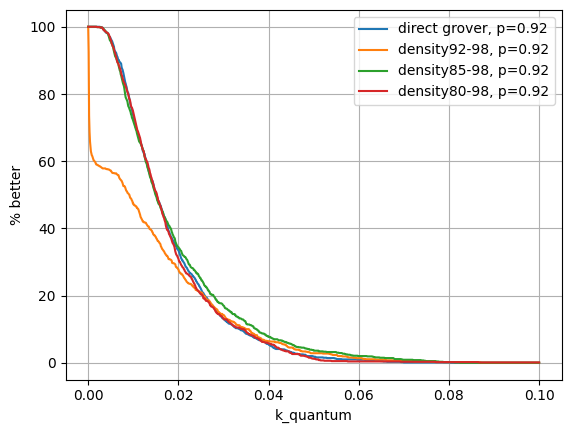

In [52]:
# fig = plot_k_quantum("benchmarkResults/hybrid/dicke_mindegree_density_n20_p092.json", label="mindegree, density, p=0.92")
# fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density_n20_p092.json", fig=fig, label="density, p=0.92")
# fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density_n20_p080.json", fig=fig, label="density, p=0.8")
# fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density_n20_p092_new.json", fig=fig, label="density, p=0.92, oracles")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_n20_p092.json", label="direct grover, p=0.92")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density92-98_n20_p092.json", fig=fig, label="density92-98, p=0.92")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density85-98_n20_p092.json", fig=fig, label="density85-98, p=0.92")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density80-98_n20_p092.json", fig=fig, label="density80-98, p=0.92")

Density condition on sparser graphs (p=0.6)

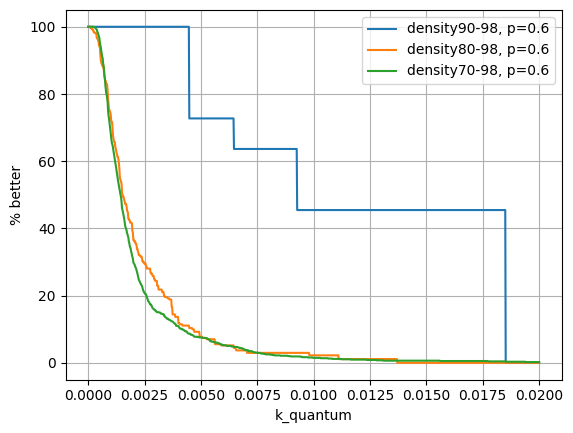

In [49]:
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density90-98_n20_p06.json", k_max=0.02, label="density90-98, p=0.6", ylim=(-5, 105))
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density80-98_n20_p06.json", k_max=0.02, fig=fig, label="density80-98, p=0.6")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density70-98_n20_p06.json", k_max=0.02, fig=fig, label="density70-98, p=0.6")

min best size condition, p=0.92

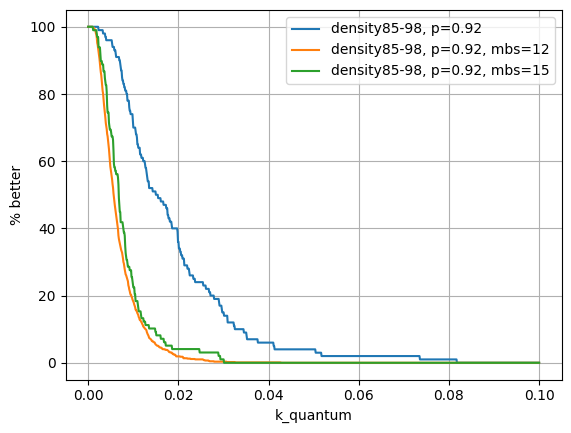

In [44]:
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density85-98_n20_p092.json", label="density85-98, p=0.92")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density85-98_minBestSize12_n20_p092.json", fig=fig, label="density85-98, p=0.92, mbs=12")
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density85-98_minBestSize15_n20_p092.json", fig=fig, label="density85-98, p=0.92, mbs=15")

min best size condition, p=0.6

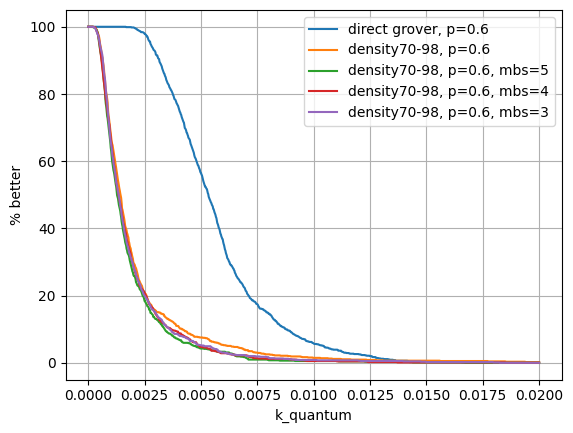

In [45]:
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_n20_p06.json", label="direct grover, p=0.6", k_max=0.02)
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density70-98_n20_p06.json", fig=fig, label="density70-98, p=0.6", k_max=0.02)
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density70-98_minBestSize5_n20_p06.json", fig=fig, label="density70-98, p=0.6, mbs=5", k_max=0.02)
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density70-98_minBestSize4_n20_p06.json", fig=fig, label="density70-98, p=0.6, mbs=4", k_max=0.02)
fig = plot_k_quantum("benchmarkResults/hybrid/dicke_density70-98_minBestSize3_n20_p06.json", fig=fig, label="density70-98, p=0.6, mbs=3", k_max=0.02)